# Assignment 15: Independent Component Analysis (ICA) for Signal Separation
**Aim:** Execute and analyse Independent Component Analysis (ICA) for blind signal separation using `sklearn.decomposition.FastICA` on synthetically generated signals. Plot the original, mixed, and recovered signals, and analyse the output (why recovered signals are not exactly the same as the originals, what happens when the number of components is wrong, and the role of Gaussian signals).  
**Tools / Libraries:** `numpy`, `matplotlib`, `scipy`, `scikit-learn` (`sklearn.decomposition.FastICA`)  
**Programming Platform / Language:** Jupyter Notebook, Python

## Theory & Task Overview

### Independent Component Analysis (ICA)
ICA is an unsupervised technique that separates a multivariate signal into additive, **statistically independent, non-Gaussian** source signals. A classic example is the *cocktail party problem*: several microphones record mixtures of several speakers, and ICA recovers each speaker's voice.

The observed (mixed) signals are modelled as:

$$X = S\,A^{T}$$

where `S` holds the unknown independent sources and `A` is the unknown mixing matrix. ICA estimates an un-mixing matrix `W` so that the recovered sources are `S_est = X W^T ≈ S`.

* **FastICA** first centres and whitens the data, then finds directions that maximise non-Gaussianity (using a negentropy approximation).
* **Source signals used here (synthetic):**
  1. `s1 = sin(2t)` : sine wave
  2. `s2 = sign(sin(3t))` : square wave
* **Mixing matrix:** `A = [[1, 1], [0.5, 2]]`
* **Key assumptions:** sources are statistically independent, at most one source is Gaussian, and the mixing is linear.

## Step 1: Generate and Mix the Signals

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kurtosis
from sklearn.decomposition import FastICA

# 1. Create the original (source) signals
t = np.linspace(0, 8, 1000)
s1 = np.sin(2 * t)             # Signal 1 : sine wave
s2 = np.sign(np.sin(3 * t))    # Signal 2 : square wave
S = np.c_[s1, s2]

# 2. Mix the signals
A = np.array([[1, 1], [0.5, 2]])
X = S @ A.T

print("Original signals shape:", S.shape)
print("Mixed signals shape   :", X.shape)

Original signals shape: (1000, 2)
Mixed signals shape   : (1000, 2)


---
## Step 2: Applying FastICA
We apply FastICA with 2 components (equal to the number of sources) to recover the signals from the mixtures.

In [2]:
ica = FastICA(n_components=2, random_state=0)
S_est = ica.fit_transform(X)       # recovered signals

print("Recovered signals shape:", S_est.shape)
print("Estimated mixing matrix:\n", np.round(ica.mixing_, 4))

Recovered signals shape: (1000, 2)
Estimated mixing matrix:
 [[1.0374 0.7179]
 [2.0158 0.4026]]


---
## Step 3: Visualizing the Original, Mixed and Recovered Signals

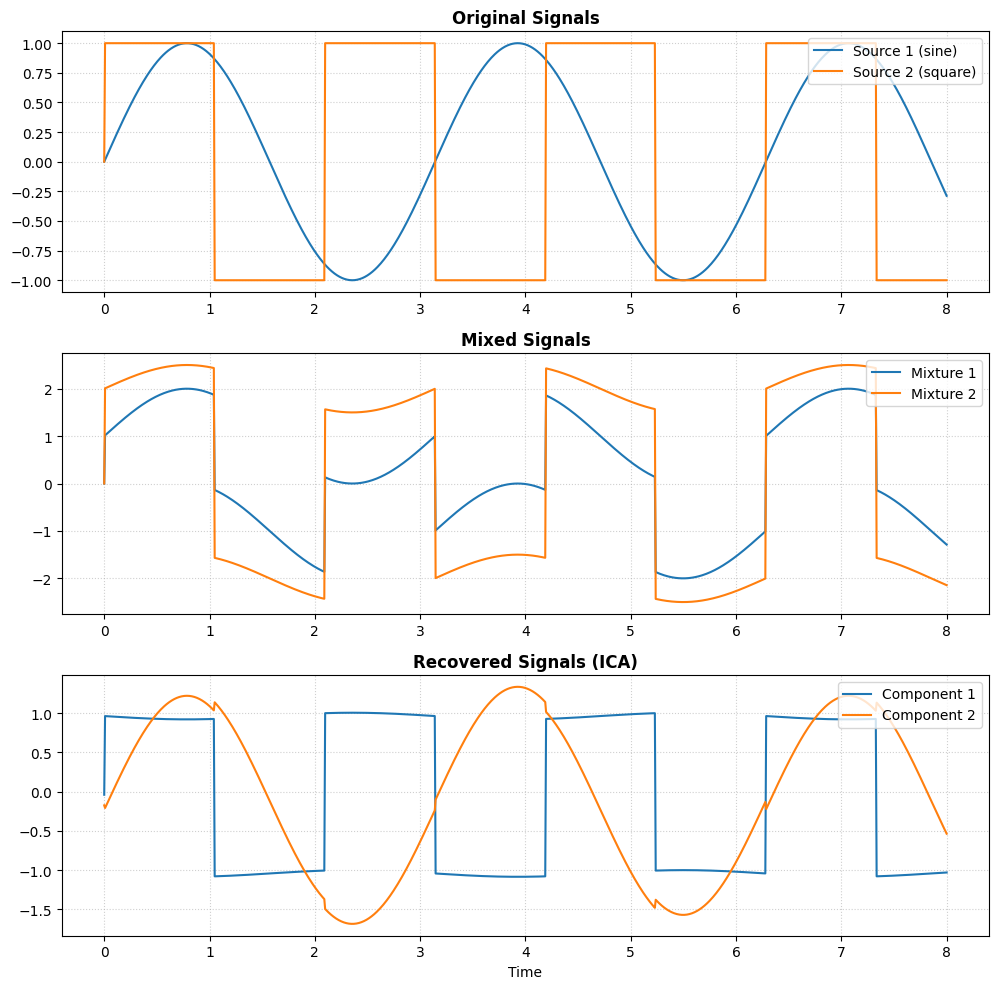

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))

axes[0].plot(t, S)
axes[0].set_title("Original Signals", fontsize=12, fontweight='bold')
axes[0].legend(['Source 1 (sine)', 'Source 2 (square)'], loc='upper right')

axes[1].plot(t, X)
axes[1].set_title("Mixed Signals", fontsize=12, fontweight='bold')
axes[1].legend(['Mixture 1', 'Mixture 2'], loc='upper right')

axes[2].plot(t, S_est)
axes[2].set_title("Recovered Signals (ICA)", fontsize=12, fontweight='bold')
axes[2].legend(['Component 1', 'Component 2'], loc='upper right')

for ax in axes:
    ax.grid(True, linestyle=':', alpha=0.6)
axes[2].set_xlabel("Time")

plt.tight_layout()
plt.show()

---
## Step 4: Are the Recovered Signals Exactly the Same as the Original?
We measure the correlation between every original signal and every recovered component, and compare their scales.

In [4]:
# Correlation between original (rows) and recovered (columns) signals
corr = np.corrcoef(S.T, S_est.T)[:2, 2:]
print("Correlation (rows: original S1,S2 | columns: recovered C1,C2):")
print(np.round(corr, 4))

print("\nStandard deviation of original signals :", np.round(S.std(axis=0), 4))
print("Standard deviation of recovered signals:", np.round(S_est.std(axis=0), 4))

Correlation (rows: original S1,S2 | columns: recovered C1,C2):
[[0.057  0.9984]
 [0.9996 0.0291]]

Standard deviation of original signals : [0.6899 0.9985]
Standard deviation of recovered signals: [1. 1.]


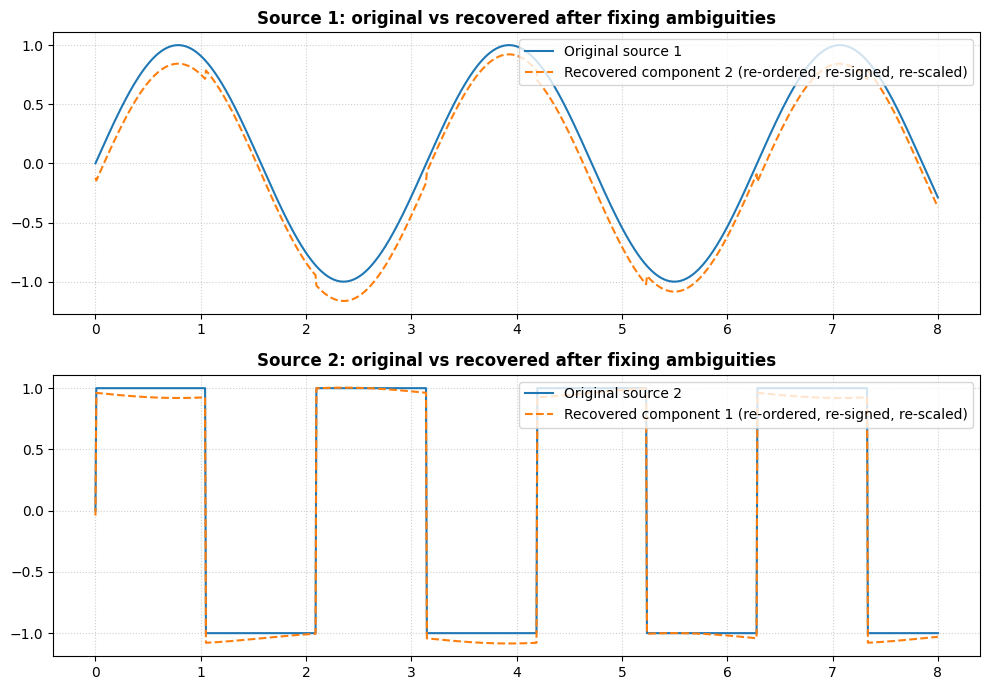

In [5]:
# Plot each recovered signal next to its best-matching original (after fixing order and sign)
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
for i in range(2):
    j = np.argmax(np.abs(corr[i]))                 # matching component (fixes permutation)
    comp = S_est[:, j] * np.sign(corr[i, j])       # fix sign
    comp = comp * S[:, i].std() / comp.std()       # fix scale
    axes[i].plot(t, S[:, i], label=f"Original source {i+1}")
    axes[i].plot(t, comp, '--', label=f"Recovered component {j+1} (re-ordered, re-signed, re-scaled)")
    axes[i].set_title(f"Source {i+1}: original vs recovered after fixing ambiguities", fontweight='bold')
    axes[i].legend(loc='upper right'); axes[i].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

---
## Step 5: What if the Number of Components is Wrong?
We have 2 mixtures and 2 true sources. Let us try `n_components = 1` (too few) and `n_components = 3` (too many).

In [6]:
import warnings

# Too few components (1 instead of 2)
ica1 = FastICA(n_components=1, random_state=0)
S_est1 = ica1.fit_transform(X)
print("n_components = 1 -> output shape:", S_est1.shape)
print("Correlation of the single component with Source 1 (sine)  :", round(np.corrcoef(S[:, 0], S_est1[:, 0])[0, 1], 4))
print("Correlation of the single component with Source 2 (square):", round(np.corrcoef(S[:, 1], S_est1[:, 0])[0, 1], 4))

# Too many components (3 instead of 2) - only 2 mixtures are available
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    S_est3 = FastICA(n_components=3, random_state=0).fit_transform(X)
print("\nn_components = 3 -> output shape:", S_est3.shape)
print("Warning raised:", [str(x.message) for x in w])

n_components = 1 -> output shape: (1000, 1)
Correlation of the single component with Source 1 (sine)  : 0.3537
Correlation of the single component with Source 2 (square): 0.9623

n_components = 3 -> output shape: (1000, 2)
Warning raised: ['n_components is too large: it will be set to 2']


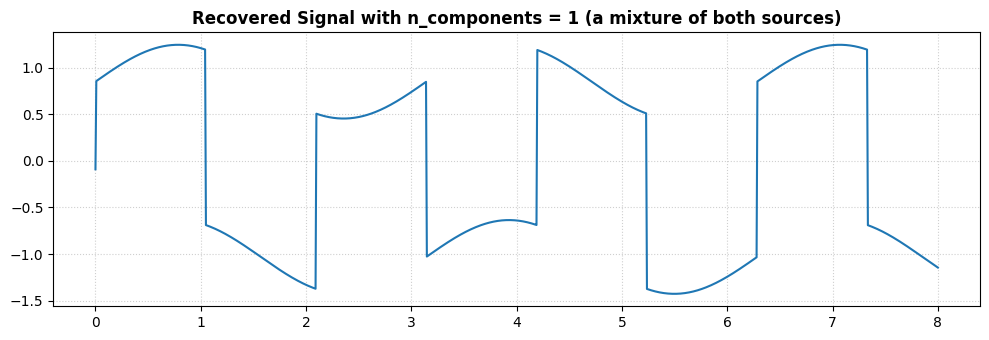

In [7]:
plt.figure(figsize=(10, 3.5))
plt.plot(t, S_est1)
plt.title("Recovered Signal with n_components = 1 (a mixture of both sources)", fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

---
## Step 6: What if the Signals are Gaussian?
We check the non-Gaussianity of our sources using **excess kurtosis** (0 for a Gaussian distribution) and then repeat ICA using Gaussian sources with different random initialisations.

In [8]:
print("Excess kurtosis of source signals (Gaussian = 0):")
print("  Sine wave  :", round(kurtosis(S[:, 0]), 3))
print("  Square wave:", round(kurtosis(S[:, 1]), 3))

# Gaussian sources
rng = np.random.default_rng(0)
G = rng.normal(size=(1000, 2))
print("\nExcess kurtosis of Gaussian sources:", np.round(kurtosis(G, axis=0), 3))
XG = G @ A.T

print("\n|Correlation| between Gaussian sources and recovered components for different seeds:")
for seed in range(5):
    GE = FastICA(n_components=2, random_state=seed, whiten='unit-variance').fit_transform(XG)
    c = np.abs(np.corrcoef(G.T, GE.T)[:2, 2:])
    print(f"  seed {seed}:", np.round(c, 3).tolist())

print("\nSame check with our non-Gaussian signals (sine + square):")
for seed in range(5):
    SE = FastICA(n_components=2, random_state=seed, whiten='unit-variance').fit_transform(X)
    c = np.abs(np.corrcoef(S.T, SE.T)[:2, 2:])
    print(f"  seed {seed}:", np.round(c, 3).tolist())

Excess kurtosis of source signals (Gaussian = 0):
  Sine wave  : -1.365
  Square wave: -1.991

Excess kurtosis of Gaussian sources: [0.002 0.074]

|Correlation| between Gaussian sources and recovered components for different seeds:
  seed 0: [[0.014, 1.0], [0.999, 0.034]]
  seed 1: [[0.018, 1.0], [0.999, 0.038]]
  seed 2: [[1.0, 0.016], [0.036, 0.999]]
  seed 3: [[0.466, 0.885], [0.894, 0.449]]
  seed 4: [[1.0, 0.016], [0.037, 0.999]]

Same check with our non-Gaussian signals (sine + square):
  seed 0: [[0.057, 0.998], [1.0, 0.029]]
  seed 1: [[0.057, 0.998], [1.0, 0.029]]
  seed 2: [[0.998, 0.057], [0.029, 1.0]]
  seed 3: [[0.057, 0.998], [1.0, 0.029]]
  seed 4: [[0.998, 0.057], [0.029, 1.0]]


---
## Analysis

### a. Explain the output. Are the recovered signals exactly the same as the original? If not, why?
* The mixed signals (Step 3, middle plot) look like tangled combinations of a sine wave and a square wave. FastICA, without knowing the mixing matrix, separates them again: one recovered component looks like the **sine wave** and the other like the **square wave**. The correlation matrix in Step 4 shows each recovered component matches exactly one original source (|correlation| ≈ 1) and almost none of the other.
* However, the recovered signals are **not exactly identical** to the originals. They match only **up to three ambiguities**, which are inherent to ICA:
  1. **Scale (amplitude) ambiguity:** since `X = S Aᵀ`, any scaling of a source can be cancelled by scaling the matching column of `A`. FastICA fixes the variance of every component to 1, so the recovered amplitudes differ from the originals (e.g. the sine has std ≈ 0.69, but the recovered component has std = 1).
  2. **Sign ambiguity:** a component multiplied by −1 is equally valid, so a recovered signal may appear upside-down.
  3. **Permutation (order) ambiguity:** ICA does not know which source was first, so the recovered components may come out in a different order (here, Component 1 matches the square wave and Component 2 the sine wave, or vice versa).
* Small differences also arise because FastICA is an **approximate, iterative** method (it uses an approximation of negentropy and a finite number of samples), so the separation is very good but not mathematically perfect.
* After correcting the order, sign, and scale (Step 4 plot), the recovered signals overlap the originals almost perfectly: the **waveform shape** is recovered, but not the original amplitude, sign, or order.

### b. What happens if the number of components is wrong? Are the signals Gaussian?
* **Too few components (n_components = 1):** the data is projected onto a single direction, so only one signal is returned and the information of the other source is lost. The output is no longer a clean source: it correlates strongly with the square wave (≈ 0.96) but also with the sine wave (≈ 0.35), so it is a leftover mixture rather than a separated signal. The sources cannot be fully recovered.
* **Too many components (n_components = 3, with only 2 mixtures):** ICA cannot create more independent components than there are observed mixtures. scikit-learn warns *"n_components is too large"* and automatically reduces it to 2. In general, if the number of components exceeds the true number of sources (when more mixtures are available), the extra components just capture noise or split a source into meaningless pieces, and the separation becomes unstable. The correct number of components should equal the number of true sources (and cannot exceed the number of observed mixtures).
* **Are the signals Gaussian?** No. The sine wave (excess kurtosis ≈ −1.37) and the square wave (≈ −1.99) are clearly **non-Gaussian** (a Gaussian has excess kurtosis 0). This is exactly why ICA works: it separates signals by maximising **non-Gaussianity**. If the sources were Gaussian (Step 6), the whitened data would be rotationally symmetric, so every rotation is equally valid and ICA cannot identify the original directions. The result then depends on the random initialisation (seed 3 above gives a mixed result, while others happen to give a clean one), which shows the separation is unreliable. At most one source may be Gaussian for ICA to work.

## Conclusion
* FastICA successfully separated the sine and square waves from their linear mixtures, but only **up to order, sign, and scale**.
* The number of components should equal the number of true sources, and the sources must be **independent and non-Gaussian** for ICA to work reliably.